# Source localization 

The aim of this lecture is to teach you how to compute and apply
a linear inverse methods such as MNE/dSPM/sLORETA and an LCMV beamformer on evoked data.
We will also look at how to extract source time courses from such a distributed source estimate, as well as fitting individual dipoles and looking at their time courses.

`
Authors: Marijn van Vliet, Britta Westner, Alexandre Gramfort, Denis Engemann 
`

In [1]:
# This makes figures appear inside the notebook instead of in a new window.
%matplotlib inline

# We set the log-level of MNE-Python to 'warning' so the output is less verbose:
import mne
mne.set_log_level('error')

# Disable all warnings so they don't end up in the HTML.
import warnings
warnings.filterwarnings("ignore")

# Specify rendering backends
mne.viz.set_browser_backend("qt")

## Setup

The same as before.

In [2]:
# These are the Python packages we will use in this session.
import numpy as np  # for numerical computations
import matplotlib.pyplot as plt  # for making custom figures
import mne  # for MEG and EEG data analysis

# Change the following path to where you extracted mne_course_data.zip
data_path = "./data"

# Based on the `data_path` you specified above, this is where the raw MEG+EEG data should be.
raw_fname = f"{data_path}/sub-01/sub-01_ses-meg_task-facerecognition_run-01_meg.fif"

# Change the following path to where you want to save the processed data.
processed_path = "./data/processed"

# This is the FreeSurfer "subjects" folder, where the program expects the MRI data to be
subjects_dir = f"{data_path}/freesurfer"

# The files related to the forward model we created earlier
trans_fname = f"{subjects_dir}/sub-01/sub-01-trans.fif"
bem_fname = f"{processed_path}/sub-01/sub-01-bem-sol.fif"

## The noise covariance

In order to perform source estimation more properly, we need to estimate the covariance between the sensors.
This is typically done on a stretch of data without experimental effects, containing only "noise", hence we refer to this covariance matrix as the "noise covariance".
In many cases, we can use the baseline period for this.

In [3]:
epochs = mne.read_epochs(f"{processed_path}/sub-01/sub-01_epo.fif")
noise_cov = mne.compute_covariance(epochs, tmin=-.2, tmax=0.,  # use the baseline
                                   rank="info")

Let's visualize our covariance matrices. We can see that they are severly rank deficient. Can you guess why?

Let's keep a mental note that we may have to take this into account later!

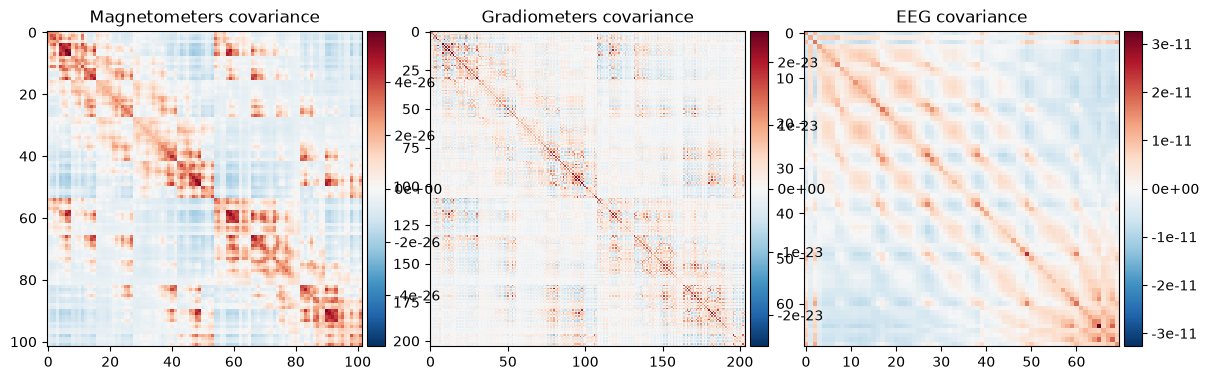

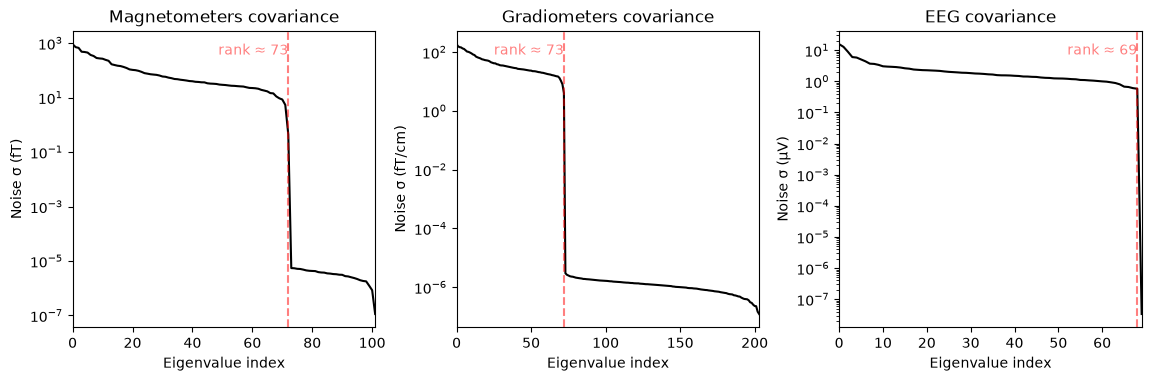

(<Figure size 1140x370 with 6 Axes>, <Figure size 1140x370 with 3 Axes>)

In [4]:
mne.viz.plot_cov(noise_cov, info=epochs.info)

We can visualize the whitening of the evoked data, using this noise covariance matrix. The signal amplitude should be around 1 during the baseline period.

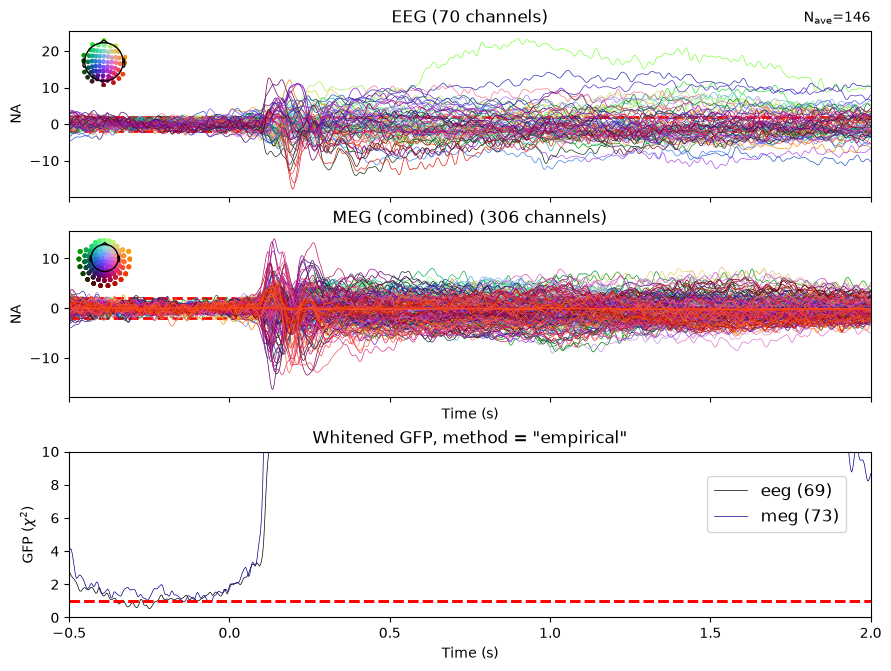

In [5]:
evoked = epochs.average()
evoked.plot_white(noise_cov);

## An initial look at the field patterns

Source estimation is typically done on the evokeds (ERP/ERF). Let's load them and crop them to 
To get an intuition of how source estimation works, it is helpful to visualize the magnetic field and play around with "manually" fitting some dipoles. MNE-Python has a GUI for that.

In [6]:
evoked_fname = f"{processed_path}/sub-01/sub-01_ave.fif"
evoked_faces = mne.read_evokeds(evoked_fname, condition="all faces")
evoked_scrambled = mne.read_evokeds(evoked_fname, condition="scrambled stimuli")

In [7]:
mne.gui.dipolefit(evoked_faces)

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Try fitting a dipole to the visual response around 122ms and the "face" response around 137ms. Can you get a goodness-of-fit above 50%?</li>
    </ul>
</div>

## Compute MNE inverse operator and apply to evoked data

To perform distributed source estimation such as MNE, we need to read the forward model that we had saved before.

In [8]:
fwd = mne.read_forward_solution(f"{processed_path}/sub-01/sub-01-fwd.fif")

Minimum norm inverse models are independent from the data (as they use just the noise covariance but not a data covariance matrix) and can therefore be precomputed and applied to the data at a later stage.

In [9]:
from mne.minimum_norm import make_inverse_operator, apply_inverse
info = evoked_faces.info  # only use MEG sensors
inverse_operator = make_inverse_operator(info, fwd, noise_cov, loose=0.2, depth=0.8)

Now let's apply this inverse operator to our evokeds:

In [10]:
method = "dSPM"  # use the MNE-dSPM method
snr = 3.
lambda2 = 1. / snr ** 2  # regularization

stc_faces = apply_inverse(evoked_faces, inverse_operator, lambda2, method=method)
stc_scrambled = apply_inverse(evoked_scrambled, inverse_operator, lambda2, method=method)

Let us plot one of the course estimates. You can explore the source reconstruction, e.g. by watching the activation as a movie.  
(keep the resulting window open for the next cell to work!)

In [11]:
brain_faces = stc_faces.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both")

When we have multiple brain plots open, we can link them together. In this manner we can compare between experimental contrasts.

In [12]:
brain_scrambled = stc_scrambled.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both")
mne.viz.link_brains([brain_faces, brain_scrambled])  # link the brain plots

Of course, the most informative plot may be the contrast between conditions.
`SourceEstimate` objects support basic math operations such as addition and subtraction.

In [13]:
stc_contrast = stc_faces - stc_scrambled
stc_contrast.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both")

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>What do the negative and positive activations mean in the contrast plot?</li>
      <li>Can you save a screenshot of the activity at 220 ms?</li>
      <li>Run sLORETA (<code>method="sLORETA"</code>) on the same data and compare source localizations.</li>
    </ul>
</div>

### About source orientations

Unlike fMRI data, MEG source estimates inherently have a direction as well as magnitude for each source point. By default, MNE-Python discards the direction and only keeps the magnitude. However, it is educational and useful to explore different ways to handling the directions.

One of the options is to just keep the directions and have a `VectorSourceEstimate` object:

In [14]:
stc_vec = apply_inverse(evoked_faces, inverse_operator, lambda2, method=method, pick_ori="vector")
stc_vec.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both", initial_time=0.166)

Since the main source of MEG activity, pyramidical neurons, tend to be aligned orthogonal to the cortical surface, a useful prior is to fix the source orientation to always be in this direction. The direction is approximated by the normal vector of the 3D mesh, hence this option is called `"normal"`:

In [15]:
stc_fixed = apply_inverse(evoked_faces, inverse_operator, lambda2, method=method, pick_ori="normal")
stc_fixed.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both", initial_time=0.166)

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>What do negative values mean in a source estimate where the orientation is always orthogonal to the cortex?</li>
      <li>Up to now, we have always plotted source estimates on an "inflated" brain. Plot the <code>stc_fixed</code> source estimate while specifying <code>surface="white"</code> to see the wrinkles in the cortex. Do you see the pattern of positive and negative values?</li>
    </ul>
</div>

### Defining regions of interest (ROIs) and extracting source timecourses

A region of interest (ROI) is defined using an [`mne.Label`](https://mne.tools/stable/generated/mne.Label.html) object. A collection of such objects is called an "annotation". There are several default annations available that you can select in the "Atlab" section of the interactive source viewer.

In [16]:
stc_faces.plot(subject="sub-01", subjects_dir=subjects_dir, hemi="both", initial_time=0.167)

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>In the interactive figure, add FreeSurfer's "aparc" annotation.</li>
      <li>Set the "Extract mode" to "mean" and try plotting the source timecourse of an ROI.</li>
    </ul>
</div>


Here is how to load ROIs and obtaining source timecourses for them using Python code:

In [17]:
labels = mne.read_labels_from_annot(parc="aparc", subject="sub-01", subjects_dir=subjects_dir)
roi_timecourses_faces = stc_faces.extract_label_time_course(labels, mode="mean", src=fwd["src"])
roi_timecourses_scrambled = stc_scrambled.extract_label_time_course(labels, mode="mean", src=fwd["src"])
print(roi_timecourses_faces.shape)

(68, 361)


With some help from matplotlib, let's plot the timecourse of the first ROI, for both conditions:

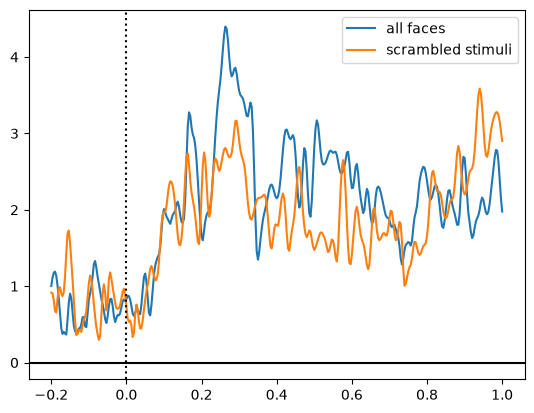

In [18]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(stc_faces.times, roi_timecourses_faces[0], label="all faces");
plt.plot(stc_scrambled.times, roi_timecourses_scrambled[0], label="scrambled stimuli");
plt.axhline(0, color="black")
plt.axvline(0, color="black", linestyle=":")
plt.legend();

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Look at the documentation for <a href="https://mne.tools/stable/generated/mne.SourceEstimate.html#mne.SourceEstimate.extract_label_time_course" target="new"><code>SourceEstimate.extract_label_time_course</code></a>. What modes are available for extracting the time course of an ROI?</li>
      <li>Try extracting the time course of the first ROI using the <code>"mean-flip"</code> mode.</li>
    </ul>
</div>

### Morphing data to an average brain for group studies

If we want to average across brains, we need to morph the data to a template brain.

In [22]:
morph = mne.compute_source_morph(stc_faces, subject_from="sub-01", subject_to="fsaverage",
                                 subjects_dir=subjects_dir)
stc_faces_fsaverage = morph.apply(stc_faces)

In [23]:
stc_faces_fsaverage.plot(subject="fsaverage", subjects_dir=subjects_dir, hemi="both")

### Saving source estimates

Source estimates can be saved like most MNE-Python objects.

In [24]:
stc_faces.save(f"{processed_path}/sub-01/sub-01_faces", overwrite=True)
stc_scrambled.save(f"{processed_path}/sub-01/sub-01_scrambled", overwrite=True)

### Using the MNE source estimate to guide dipole fitting

The dipole fitting gui can use all the details about the head model and even the MNE source estimate to guide us.

In [25]:
gui = mne.gui.dipolefit(evoked_faces, stc=stc_faces,
                  ch_type="meg", bem=bem_fname, trans=trans_fname, cov=noise_cov, rank="info",
                  subjects_dir=subjects_dir, subject="sub-01")

In [ ]:
# Save the dipoles.
gui.save(f"{processed_path}/sub-01/sub-01_dip.dip")

## LCMV beamforming

Beamformering is a source estimation method that operates differently from the family of minimum norm estimates (MNEs). Instead of mapping all sensor data to the given source space, a beamformer goes source-by-source and estimates which part of the sensor signal could plausibly originate from it. This means:
- activity from outside the brain is never assigned to any source point 😀
- the same sensor activity can be mapped to two source points at the same time 😧
- restricting the source space to the cortex is less useful
- beamforming is particularly suited for volumetric source estimation

Let's do some beamforming!

We can set up a volumetric source space like this:

In [26]:
src_vol = mne.setup_volume_source_space("sub-01", surface=f"{subjects_dir}/sub-01/bem/brain.surf", subjects_dir=subjects_dir, n_jobs=-1)
src_vol.plot(subjects_dir=subjects_dir)

We need a new forward model for this new source space:

In [27]:
fwd_vol = mne.make_forward_solution(epochs.info, trans=trans_fname, src=src_vol, bem=bem_fname, n_jobs=-1)

An LCMV beamformer needs the sensor-to-sensor covariance matrix computed during the time that interesting things are happening, so the opposite of the noise covariance matrix which was estimated during the baseline. 

In [53]:
data_cov = mne.compute_covariance(epochs, tmin=0, tmax=1.0, rank="info")

The MNE-API for beamformers works in a similar fashion as with MNE inverse solutions, we first design the LCMV beamformer once...

In [54]:
lcmv = mne.beamformer.make_lcmv(epochs.info, fwd_vol, data_cov, reg=0.05, noise_cov=noise_cov)

...and then we can apply it multiple times:

In [58]:
stc_vol_scrambled = mne.beamformer.apply_lcmv(evoked_scrambled, lcmv)
stc_vol_faces = mne.beamformer.apply_lcmv(evoked_faces, lcmv)

When plotting volumetric source estimates, you need to specify the (volumetric) source space that you used:

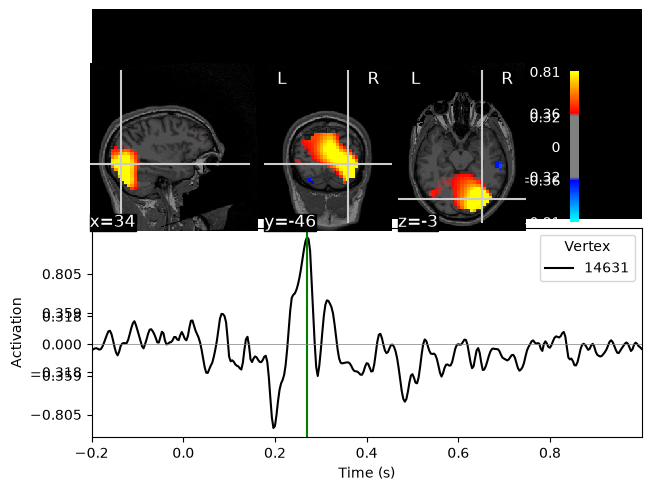

In [61]:
(stc_vol_scrambled - stc_vol_faces).plot(src_vol, subjects_dir=subjects_dir);

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
      <li>Compute the data covariance matric for different time windows by modifying the <code>tmin</code> and <code>tmax</code> parameters of <code>mne.compute_covariance</code>. What effect does your choice of time window have on the beamformer and the resulting volumetric source estimates?
    </ul>
</div